In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#import the data set
df = pd.read_csv("/content/seasonal_agriculture_performance_dataset (2).csv")
df.head() #first five rows

,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,...,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,...,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,...,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,...,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,...,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3


In [ ]:
df.tail() #last five rows

,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
3995,SF13996,Karnataka,Rajkot,Wheat,Kharif,4.72,865.4,27.3,51.4,6.3,...,0.74,0.51,2.41,22717,362917,54748,-308169,2016,1.195,45.2
3996,SF13997,Karnataka,Krishna,Chilli,Kharif,8.77,947.5,29.2,85.5,6.1,...,0.80,2.75,24.12,106459,496471,2567791,2071320,5351,4.508,59.7
3997,SF13998,Andhra Pradesh,Erode,Pulses,Zaid,10.47,80.0,35.4,68.5,8.6,...,0.99,0.62,6.49,66860,785632,433921,-351711,3392,1.913,29.2
3998,SF13999,Punjab,Warangal,Cotton,Kharif,1.73,475.0,28.2,61.7,6.4,...,0.98,1.35,2.34,75282,153904,176160,22256,1220,1.918,50.4
3999,SF14000,Punjab,Nashik,Wheat,Kharif,3.31,984.3,25.8,77.2,5.9,...,0.99,2.36,7.81,28812,263872,225022,-38850,1800,4.339,62.3


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   object 
 1   State                          4000 non-null   object 
 2   District                       4000 non-null   object 
 3   Crop                           4000 non-null   object 
 4   Season                         4000 non-null   object 
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha                 4000 non-null   f

In [ ]:
df.dtypes #Datatypes of each Column

,0
Farm_ID,object
State,object
District,object
Crop,object
Season,object
Farm_Area_Hectares,float64
Rainfall_mm,float64
Avg_Temperature_C,float64
Humidity_pct,float64
Sunlight_Hours_Day,float64


In [ ]:
df.describe() #statistical view

,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
count,4000.000000,3952.000000,4000.00000,4000.000000,4000.000000,4000.000000,3960.000000,4000.000000,4000.000000,4000.000000,...,4000.000000,3968.000000,4000.000000,4000.000000,4.000000e+03,4.000000e+03,4.000000e+03,4000.000000,4000.000000,4000.000000
mean,7.888265,601.152657,26.81890,63.210500,7.323050,6.701010,26.508232,120.250825,57.781850,104.760050,...,0.826138,5.270595,43.246210,44714.166250,5.263036e+05,6.378600e+05,1.115565e+05,6045.570250,5.385214,46.365875
std,4.223764,288.925025,3.81818,11.960834,1.121186,0.641461,6.712484,31.216452,17.015074,27.742681,...,0.101747,13.361398,126.880521,30266.161922,2.944191e+05,6.369747e+05,5.450819e+05,5572.944306,8.838101,12.424417
min,0.500000,80.000000,16.20000,25.000000,3.500000,5.200000,8.000000,40.000000,15.000000,30.000000,...,0.650000,0.300000,0.150000,2594.000000,2.682600e+04,6.107000e+03,-1.019223e+06,128.000000,0.135000,5.000000
25%,4.260000,370.200000,23.90000,54.775000,6.600000,6.260000,21.700000,98.500000,46.200000,86.200000,...,0.740000,1.050000,5.020000,21429.250000,2.745775e+05,2.075172e+05,-1.487318e+05,2268.750000,1.661000,37.300000
50%,7.895000,582.000000,26.90000,63.000000,7.300000,6.690000,26.400000,120.100000,57.500000,105.100000,...,0.830000,1.740000,11.770000,25913.000000,5.190825e+05,4.568305e+05,3.673000e+03,4435.000000,2.937500,46.400000
75%,11.650000,834.950000,29.60000,71.900000,8.100000,7.140000,31.300000,141.225000,69.400000,123.600000,...,0.910000,2.840000,24.355000,68279.000000,7.619965e+05,8.368748e+05,2.161878e+05,7829.750000,5.150250,54.900000
max,15.000000,1395.200000,39.70000,95.000000,11.000000,8.400000,47.000000,220.000000,120.000000,200.000000,...,1.000000,101.440000,1424.400000,131240.000000,1.349990e+06,5.080900e+06,4.345421e+06,40902.000000,79.800000,88.900000


In [ ]:
df.isnull().sum() #checking null values

,0
Farm_ID,0
State,0
District,0
Crop,0
Season,0
Farm_Area_Hectares,0
Rainfall_mm,48
Avg_Temperature_C,0
Humidity_pct,0
Sunlight_Hours_Day,0


In [ ]:
#recover from null values
df['Rainfall_mm'] = df['Rainfall_mm'].fillna(df['Rainfall_mm'].median())
df['Soil_Moisture_pct'] = df['Soil_Moisture_pct'].fillna(df['Soil_Moisture_pct'].median())
df['Yield_Tonnes_Ha'] = df['Yield_Tonnes_Ha'].fillna(df['Yield_Tonnes_Ha'].median())

In [ ]:
df.isnull().sum()

,0
Farm_ID,0
State,0
District,0
Crop,0
Season,0
Farm_Area_Hectares,0
Rainfall_mm,0
Avg_Temperature_C,0
Humidity_pct,0
Sunlight_Hours_Day,0


In [ ]:
df.shape

(4000, 28)

In [ ]:
df.duplicated().sum()

np.int64(0)

array([[<Axes: title={'center': 'Farm_Area_Hectares'}>,
        <Axes: title={'center': 'Rainfall_mm'}>,
        <Axes: title={'center': 'Avg_Temperature_C'}>,
        <Axes: title={'center': 'Humidity_pct'}>,
        <Axes: title={'center': 'Sunlight_Hours_Day'}>],
       [<Axes: title={'center': 'Soil_pH'}>,
        <Axes: title={'center': 'Soil_Moisture_pct'}>,
        <Axes: title={'center': 'Nitrogen_kg_ha'}>,
        <Axes: title={'center': 'Phosphorus_kg_ha'}>,
        <Axes: title={'center': 'Potassium_kg_ha'}>],
       [<Axes: title={'center': 'Fertilizer_kg_ha'}>,
        <Axes: title={'center': 'Pesticide_Litre_ha'}>,
        <Axes: title={'center': 'Seed_Quality_Score'}>,
        <Axes: title={'center': 'Yield_Tonnes_Ha'}>,
        <Axes: title={'center': 'Production_Tonnes'}>],
       [<Axes: title={'center': 'Market_Price_INR_Tonne'}>,
        <Axes: title={'center': 'Total_Cost_INR'}>,
        <Axes: title={'center': 'Revenue_INR'}>,
        <Axes: title={'center': 'Prof

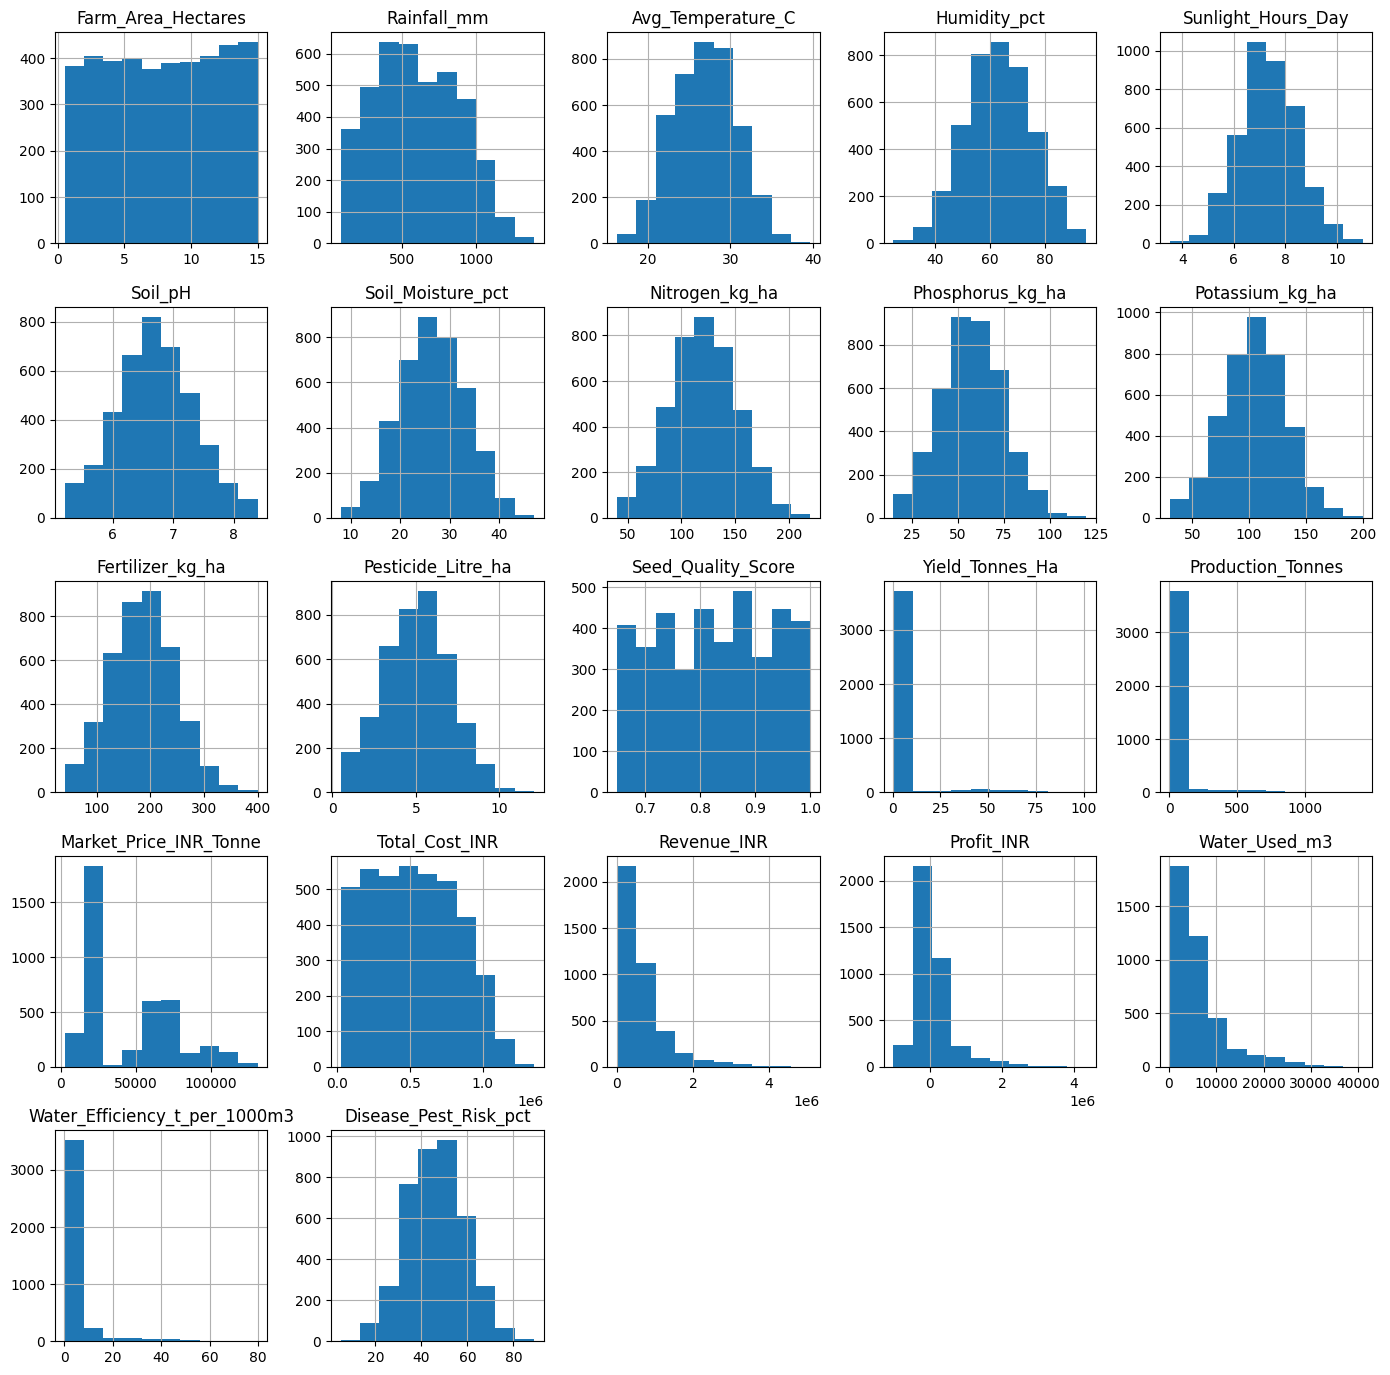

In [ ]:
#Histogram chart for each Column
df.hist(bins=10, figsize = (17,17))


In [ ]:
#Agriculture performance across Seasons
df.groupby('Season')['Yield_Tonnes_Ha'].mean()

,Yield_Tonnes_Ha
Season,
Kharif,5.628612
Rabi,5.039435
Zaid,4.641313


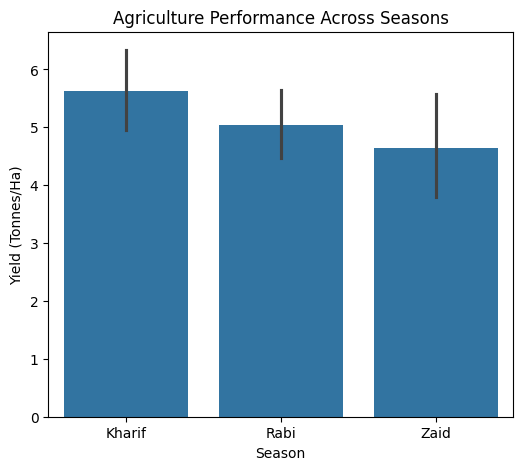

In [ ]:
plt.figure(figsize=(6,5))
sns.barplot(x='Season', y='Yield_Tonnes_Ha', data=df)
plt.title('Agriculture Performance Across Seasons')
plt.xlabel('Season')
plt.ylabel('Yield (Tonnes/Ha)')
plt.show()

In [ ]:
#Seasonal patterns
season_pattern = df.groupby('Season')[
['Yield_Tonnes_Ha',
 'Rainfall_mm',
 'Avg_Temperature_C',
 'Humidity_pct',
 'Soil_Moisture_pct',
 'Production_Tonnes',
 'Profit_INR']
].mean()
season_pattern

,Yield_Tonnes_Ha,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Soil_Moisture_pct,Production_Tonnes,Profit_INR
Season,,,,,,,
Kharif,5.628612,849.199663,28.454019,71.812591,31.149859,46.311192,178914.647555
Rabi,5.039435,437.615366,23.489183,57.893178,24.069392,41.486712,87689.470191
Zaid,4.641313,304.654714,31.042088,52.012121,19.279630,38.886111,-24804.824916


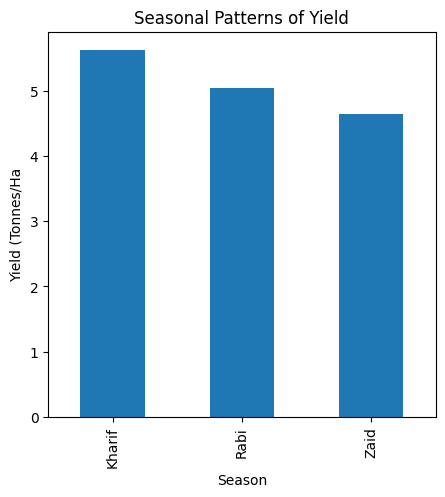

In [ ]:
season_pattern['Yield_Tonnes_Ha'].plot(kind='bar', figsize=(5,5))
plt.title('Seasonal Patterns of Yield')
plt.xlabel('Season')
plt.ylabel('Yield (Tonnes/Ha')
plt.show()

In [ ]:
#Comparison of environmental conditions

df.groupby('Season')[
['Rainfall_mm',
 'Avg_Temperature_C',
 'Humidity_pct',
 'Soil_Moisture_pct']
].mean()

,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Soil_Moisture_pct
Season,,,,
Kharif,849.199663,28.454019,71.812591,31.149859
Rabi,437.615366,23.489183,57.893178,24.069392
Zaid,304.654714,31.042088,52.012121,19.279630


In [ ]:
#variation in resources
#water usage
df.groupby('Season')['Water_Used_m3'].mean()

,Water_Used_m3
Season,
Kharif,6102.201237
Rabi,5846.987093
Zaid,6419.893939


In [ ]:
#fertilizer usage
df.groupby('Season')['Fertilizer_kg_ha'].mean()


,Fertilizer_kg_ha
Season,
Kharif,187.077965
Rabi,185.407068
Zaid,184.638047


In [ ]:
#pesticide usage
df.groupby('Season')['Pesticide_Litre_ha'].mean()

,Pesticide_Litre_ha
Season,
Kharif,5.079747
Rabi,5.024690
Zaid,5.171212


In [ ]:
#nutrients
df.groupby('Season')[
['Nitrogen_kg_ha',
 'Phosphorus_kg_ha',
 'Potassium_kg_ha']
].mean()

,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha
Season,,,
Kharif,120.020124,58.096515,105.303485
Rabi,120.402827,57.311002,103.926060
Zaid,120.525421,58.129125,105.416835


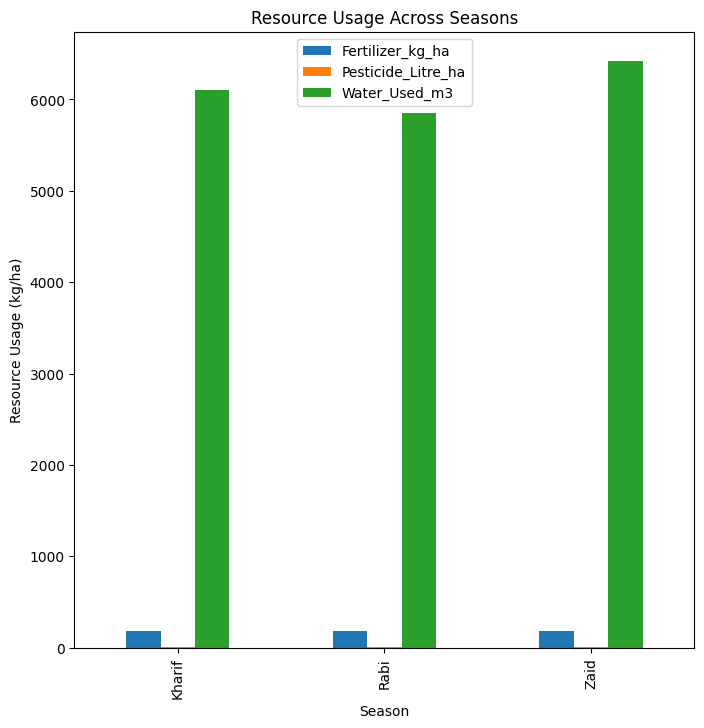

In [ ]:
resource= df.groupby('Season')[
['Fertilizer_kg_ha',
 'Pesticide_Litre_ha',
 'Water_Used_m3']
].mean()
resource.plot(kind='bar', figsize=(8,8))
plt.title('Resource Usage Across Seasons')
plt.xlabel('Season')
plt.ylabel('Resource Usage (kg/ha)')
plt.show()

In [ ]:
#Rainfall vs Yield
df[['Rainfall_mm', 'Yield_Tonnes_Ha']].corr()

,Rainfall_mm,Yield_Tonnes_Ha
Rainfall_mm,1.000000,0.030951
Yield_Tonnes_Ha,0.030951,1.000000


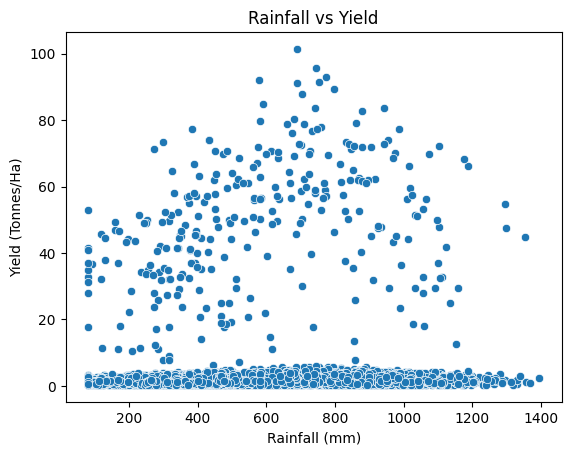

In [ ]:
sns.scatterplot(x='Rainfall_mm', y='Yield_Tonnes_Ha', data=df)
plt.title('Rainfall vs Yield')
plt.xlabel('Rainfall (mm)')
plt.ylabel('Yield (Tonnes/Ha)')
plt.show()


In [ ]:
# Temperature vs Yield
df[['Avg_Temperature_C', 'Yield_Tonnes_Ha']].corr()

,Avg_Temperature_C,Yield_Tonnes_Ha
Avg_Temperature_C,1.000000,0.009996
Yield_Tonnes_Ha,0.009996,1.000000


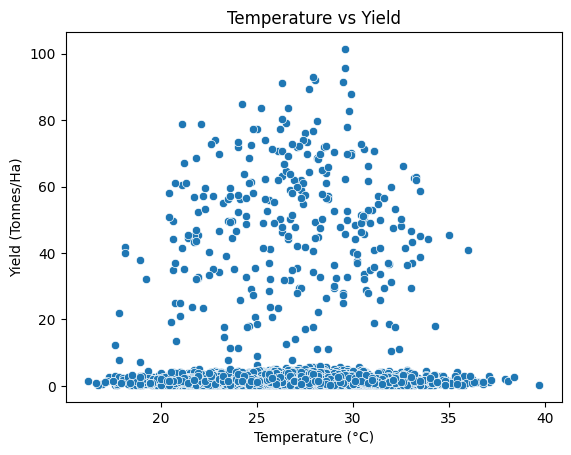

In [ ]:
sns.scatterplot(x='Avg_Temperature_C', y='Yield_Tonnes_Ha', data=df)
plt.title('Temperature vs Yield')
plt.xlabel('Temperature (°C)')
plt.ylabel('Yield (Tonnes/Ha)')
plt.show()

In [ ]:
# Soil moisture vs Yield
df[['Soil_Moisture_pct', 'Yield_Tonnes_Ha']].corr()

,Soil_Moisture_pct,Yield_Tonnes_Ha
Soil_Moisture_pct,1.000000,0.010999
Yield_Tonnes_Ha,0.010999,1.000000


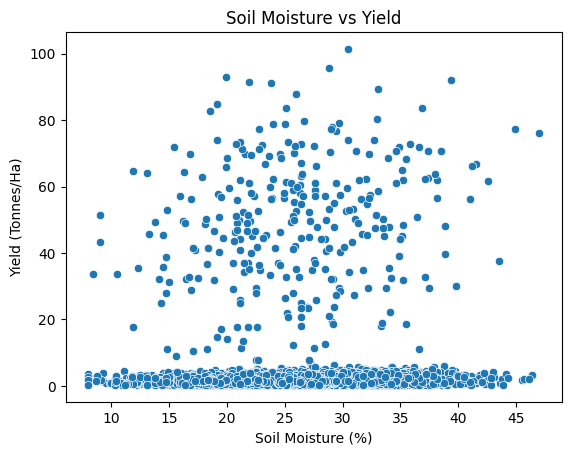

In [ ]:
sns.scatterplot(x='Soil_Moisture_pct', y='Yield_Tonnes_Ha', data=df)
plt.title('Soil Moisture vs Yield')
plt.xlabel('Soil Moisture (%)')
plt.ylabel('Yield (Tonnes/Ha)')
plt.show()

In [ ]:
# Economic outcomes across seasons
#Revenue
df.groupby('Season')['Revenue_INR'].mean()

,Revenue_INR
Season,
Kharif,710719.055649
Rabi,601526.048556
Zaid,519171.904040


In [ ]:
#Cost
df.groupby('Season')['Total_Cost_INR'].mean().sort_values(ascending=False)

,Total_Cost_INR
Season,
Zaid,543976.728956
Kharif,531804.408094
Rabi,513836.578365


In [ ]:
# Profit
df.groupby('Season')['Profit_INR'].mean()

,Profit_INR
Season,
Kharif,178914.647555
Rabi,87689.470191
Zaid,-24804.824916


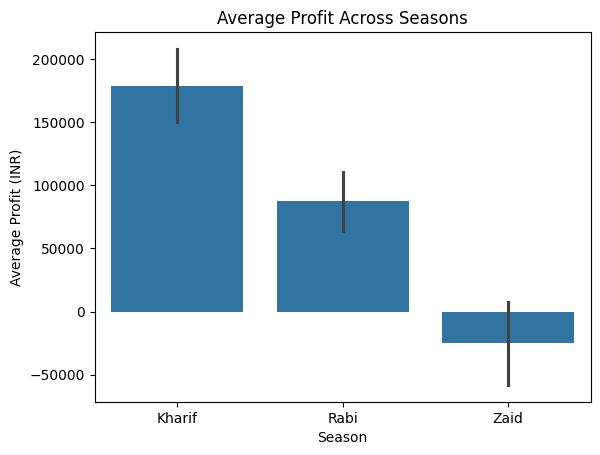

In [ ]:
sns.barplot(x='Season', y='Profit_INR', data=df)
plt.title('Average Profit Across Seasons')
plt.xlabel('Season')
plt.ylabel('Average Profit (INR)')
plt.show()

In [ ]:
# Seasonal patterns across different regions
#by state
state = df.groupby(['State','Season'])['Yield_Tonnes_Ha'].mean()
state

State           Season
Andhra Pradesh  Kharif    5.676958
                Rabi      3.470931
                Zaid      4.448000
Gujarat         Kharif    6.338416
                Rabi      5.441700
                Zaid      4.066716
Karnataka       Kharif    6.455024
                Rabi      4.567864
                Zaid      6.623243
Madhya Pradesh  Kharif    5.985265
                Rabi      3.760385
                Zaid      5.478889
Maharashtra     Kharif    5.430315
                Rabi      5.501927
                Zaid      2.277778
Punjab          Kharif    4.100633
                Rabi      8.609355
                Zaid      5.909610
Tamil Nadu      Kharif    5.520534
                Rabi      4.501394
                Zaid      4.097746
Telangana       Kharif    5.552436
                Rabi      4.784569
                Zaid      4.248471
Name: Yield_Tonnes_Ha, dtype: float64

In [ ]:
pd.pivot_table(df, values='Yield_Tonnes_Ha', index='State', columns='Season',aggfunc='mean')
#

Season,Kharif,Rabi,Zaid
State,,,
Andhra Pradesh,5.676958,3.470931,4.448000
Gujarat,6.338416,5.441700,4.066716
Karnataka,6.455024,4.567864,6.623243
Madhya Pradesh,5.985265,3.760385,5.478889
Maharashtra,5.430315,5.501927,2.277778
Punjab,4.100633,8.609355,5.909610
Tamil Nadu,5.520534,4.501394,4.097746
Telangana,5.552436,4.784569,4.248471


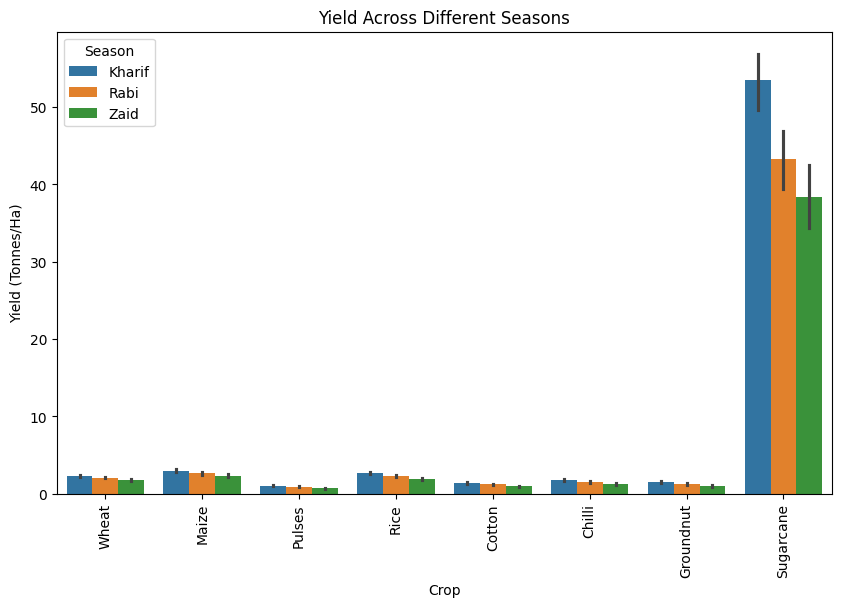

In [ ]:
#differnce b/w crops in differ seasons
plt.figure(figsize=(10,6))
sns.barplot(x='Crop', y='Yield_Tonnes_Ha', hue='Season', data=df)
plt.title('Yield Across Different Seasons')
plt.xlabel('Crop')
plt.ylabel('Yield (Tonnes/Ha)')
plt.xticks(rotation=90)
plt.show()


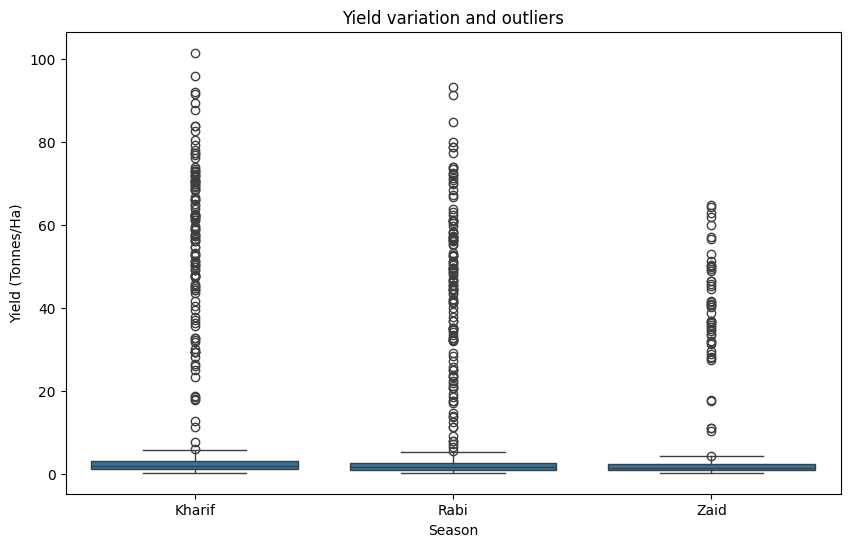

In [ ]:
#unusual pattern
plt.figure(figsize=(10,6))
sns.boxplot(x='Season', y='Yield_Tonnes_Ha', data=df)
plt.title('Yield variation and outliers')
plt.xlabel('Season')
plt.ylabel('Yield (Tonnes/Ha)')
plt.show()

In [ ]:
# variables most related to agricultural performance
variable = df[
    ['Rainfall_mm',
     'Avg_Temperature_C',
     'Humidity_pct',
     'Sunlight_Hours_Day',
     'Soil_pH',
     'Soil_Moisture_pct',
     'Fertilizer_kg_ha',
     'Pesticide_Litre_ha',
     'Water_Used_m3',
     'Yield_Tonnes_Ha',
     'Production_Tonnes',
     'Profit_INR']
].corr()


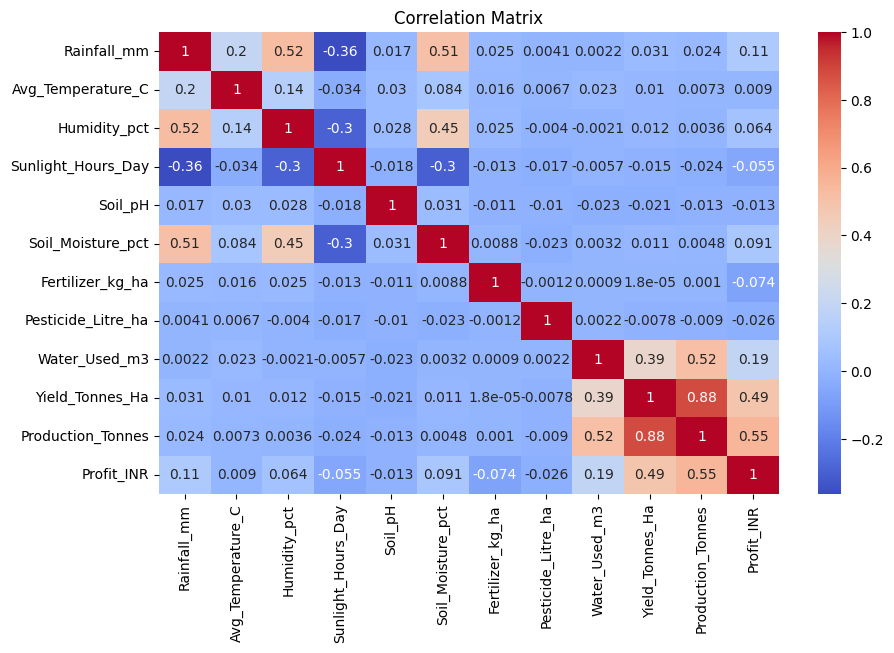

In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(variable, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [ ]:
#best performing season
performance = df.groupby('Season')[
['Yield_Tonnes_Ha',
 'Production_Tonnes',
 'Water_Efficiency_t_per_1000m3',
 'Revenue_INR',
 'Profit_INR']
].mean()
performance

,Yield_Tonnes_Ha,Production_Tonnes,Water_Efficiency_t_per_1000m3,Revenue_INR,Profit_INR
Season,,,,,
Kharif,5.628612,46.311192,5.891834,710719.055649,178914.647555
Rabi,5.039435,41.486712,5.186122,601526.048556,87689.470191
Zaid,4.641313,38.886111,4.413239,519171.904040,-24804.824916


In [ ]:
performance.sort_values(by='Yield_Tonnes_Ha', ascending=False)

,Yield_Tonnes_Ha,Production_Tonnes,Water_Efficiency_t_per_1000m3,Revenue_INR,Profit_INR
Season,,,,,
Kharif,5.628612,46.311192,5.891834,710719.055649,178914.647555
Rabi,5.039435,41.486712,5.186122,601526.048556,87689.470191
Zaid,4.641313,38.886111,4.413239,519171.904040,-24804.824916


In [ ]:
performance.sort_values(by='Profit_INR', ascending=False)

,Yield_Tonnes_Ha,Production_Tonnes,Water_Efficiency_t_per_1000m3,Revenue_INR,Profit_INR
Season,,,,,
Kharif,5.628612,46.311192,5.891834,710719.055649,178914.647555
Rabi,5.039435,41.486712,5.186122,601526.048556,87689.470191
Zaid,4.641313,38.886111,4.413239,519171.904040,-24804.824916
